# Analyse en composantes principales — Agriculture CropYield

Le sujet demande une ACP sur ce jeu pour « identifier les variables clés ». On la mène en
deux passes : d'abord **avec la cible**, pour lire la structure globale des relations,
puis **sans la cible**, pour juger de l'intérêt d'une réduction de dimension avant
modélisation.

# Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent))

from src import config, utils
from src.data import preparation

utils.style()
np.random.seed(config.SEED)

# Données

In [2]:
# Only the boolean typing is applied: no row is discarded at this stage,
# since the EDA decisions are only settled in notebook 06.
df = preparation.typage(preparation.charge())
print(f"{df.shape[0]:,} lignes x {df.shape[1]} colonnes")

1,000,000 lignes x 10 colonnes


## Variables retenues

Une ACP porte sur des variables quantitatives. Les quatre variables nominales —
`Region`, `Soil_Type`, `Crop`, `Weather_Condition` — sont **écartées** : leur attribuer
des valeurs numériques créerait de fausses distances. Elles ont été examinées dans le
notebook 01, qui n'y a trouvé aucun effet.

**Choix retenus**

- `Fertilizer_Used`, `Irrigation_Used` : booléens convertis en 0/1, puis standardisés
  avec les autres.
- `Days_to_Harvest` : conservée, pour observer sa place dans la structure globale.
- `Yield_tons_per_hectare` : conservée dans la **première** passe uniquement, afin de
  lire ses relations avec les autres variables.

Le rendement devrait en revanche être écarté si l'ACP servait de prétraitement à un
modèle supervisé, sous peine de fuite de données. D'où la seconde passe.

In [3]:
colonnes_acp = [
    "Rainfall_mm",
    "Temperature_Celsius",
    "Fertilizer_Used",
    "Irrigation_Used",
    "Days_to_Harvest",
    preparation.CIBLE,
]
X = df[colonnes_acp].astype(float)   # converts the two booleans to 0.0 / 1.0
print("valeurs manquantes :", int(X.isna().sum().sum()))
print("dimensions         :", X.shape)
X.head()

valeurs manquantes : 0
dimensions         : (1000000, 6)


,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Days_to_Harvest,Yield_tons_per_hectare
0,897.077239,27.676966,0.0,1.0,122.0,6.555816
1,992.673282,18.026142,1.0,1.0,140.0,8.527341
2,147.998025,29.794042,0.0,0.0,106.0,1.127443
3,986.866331,16.644190,0.0,1.0,146.0,6.517573
4,730.379174,31.620687,1.0,1.0,110.0,7.248251


## Corrélations de départ

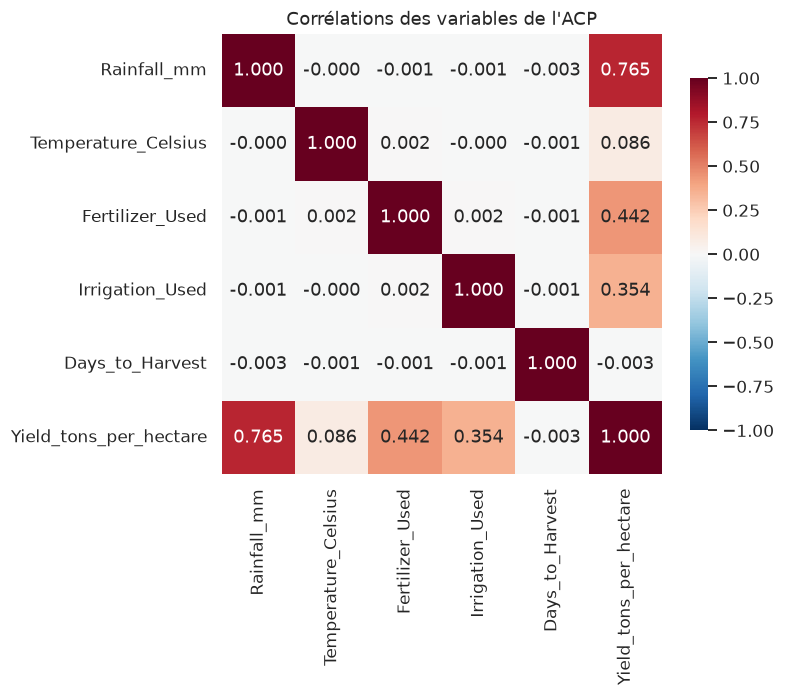

In [4]:
fig, ax = plt.subplots(figsize=(6.6, 5.2))
sns.heatmap(X.corr(), annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Corrélations des variables de l'ACP")
plt.show()

**Observations :** hors cible, toutes les corrélations croisées sont nulles. Seule la
cible est corrélée à trois variables. L'ACP ne pourra donc structurer que ce lien.

## Standardisation

In [5]:
# The units are not comparable at all (mm, °C, days, 0/1): standardisation is
# essential, otherwise rainfall would dominate everything through its scale alone.
X_std = StandardScaler().fit_transform(X)
print("moyennes après standardisation :", np.abs(X_std.mean(axis=0)).max().round(12))
print("écarts-types                   :", X_std.std(axis=0).round(6))

moyennes après standardisation : 0.0
écarts-types                   : [1. 1. 1. 1. 1. 1.]


# ACP

In [6]:
acp = PCA(random_state=config.SEED).fit(X_std)
variance = pd.DataFrame({
    "axe": [f"F{i+1}" for i in range(acp.n_components_)],
    "variance expliquée (%)": (acp.explained_variance_ratio_ * 100).round(2),
    "cumul (%)": (acp.explained_variance_ratio_.cumsum() * 100).round(2),
})
variance

,axe,variance expliquée (%),cumul (%)
0,F1,32.58,32.58
1,F2,16.71,49.30
2,F3,16.68,65.98
3,F4,16.67,82.64
4,F5,16.62,99.26
5,F6,0.74,100.00


## Variance expliquée

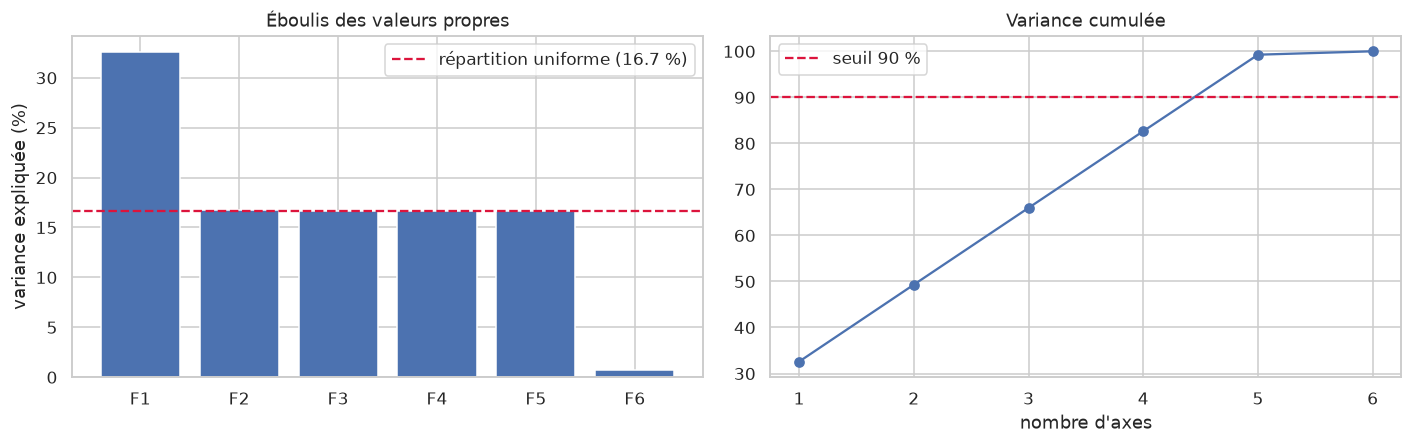

axes nécessaires pour 90 % : 5 sur 6


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].bar(variance["axe"], variance["variance expliquée (%)"], color="#4C72B0")
axes[0].axhline(100 / len(colonnes_acp), ls="--", c="crimson",
                label=f"répartition uniforme ({100/len(colonnes_acp):.1f} %)")
axes[0].set_title("Éboulis des valeurs propres")
axes[0].set_ylabel("variance expliquée (%)")
axes[0].legend()

axes[1].plot(range(1, len(colonnes_acp) + 1), variance["cumul (%)"], marker="o")
axes[1].axhline(90, ls="--", c="crimson", label="seuil 90 %")
axes[1].set_title("Variance cumulée")
axes[1].set_xlabel("nombre d'axes")
axes[1].set_xticks(range(1, len(colonnes_acp) + 1))
axes[1].legend()
utils.enregistre("02_eboulis")
plt.show()

print(f"axes nécessaires pour 90 % : {int((variance['cumul (%)'] < 90).sum() + 1)} "
      f"sur {len(colonnes_acp)}")

**Observations :**

- **F1 est le seul axe qui se détache** : il porte nettement plus que la part uniforme.
- Les axes suivants se répartissent le reste de façon presque égale.
- C'est la cible qui crée cette structure : elle seule est corrélée à plusieurs variables.
- **F6 ne porte que 0,74 % de la variance.** Autrement dit, les six variables sont presque
  parfaitement liées linéairement : le rendement est, à peu de chose près, une combinaison
  linéaire des cinq autres. C'est une mesure directe du mode de génération du jeu, et cela
  confirme l'hypothèse formulée au notebook 01 — une régression linéaire devrait très bien
  fonctionner, et le résidu de 0,74 % borne le bruit du générateur.

## Contrôle sans la cible

In [8]:
colonnes_sans_cible = [c for c in colonnes_acp if c != preparation.CIBLE]
X_sans_cible = StandardScaler().fit_transform(df[colonnes_sans_cible].astype(float))
acp_sans_cible = PCA(random_state=config.SEED).fit(X_sans_cible)

pd.DataFrame({
    "axe": [f"F{i+1}" for i in range(acp_sans_cible.n_components_)],
    "variance expliquée (%)": (acp_sans_cible.explained_variance_ratio_ * 100).round(2),
    "cumul (%)": (acp_sans_cible.explained_variance_ratio_.cumsum() * 100).round(2),
})

,axe,variance expliquée (%),cumul (%)
0,F1,20.07,20.07
1,F2,20.05,40.12
2,F3,20.01,60.13
3,F4,19.94,80.07
4,F5,19.93,100.00


**Observations :**

- Environ **20 % de variance par axe**, soit exactement la répartition uniforme : aucun
  axe ne domine, et **les cinq axes sont nécessaires** pour atteindre 90 %.
- Les variables explicatives sont donc mutuellement indépendantes et apportent des
  dimensions distinctes.
- **L'ACP n'a aucun intérêt comme réduction de dimension avant modélisation** : il n'y a
  rien à compresser. Ce n'est pas un échec de l'analyse, c'est une mesure — et elle
  interdit d'appliquer une réduction de dimension à l'étape 2.

# Interprétation des axes

## Corrélations variables / axes

In [9]:
charges = pd.DataFrame(
    acp.components_[:3].T * np.sqrt(acp.explained_variance_[:3]),
    index=colonnes_acp, columns=["F1", "F2", "F3"],
)
charges.round(3)

,F1,F2,F3
Rainfall_mm,0.791,-0.545,-0.222
Temperature_Celsius,0.089,0.479,-0.632
Fertilizer_Used,0.458,0.635,-0.012
Irrigation_Used,0.366,0.268,0.649
Days_to_Harvest,-0.006,0.043,0.361
Yield_tons_per_hectare,0.989,-0.001,0.001


## Cercle des corrélations

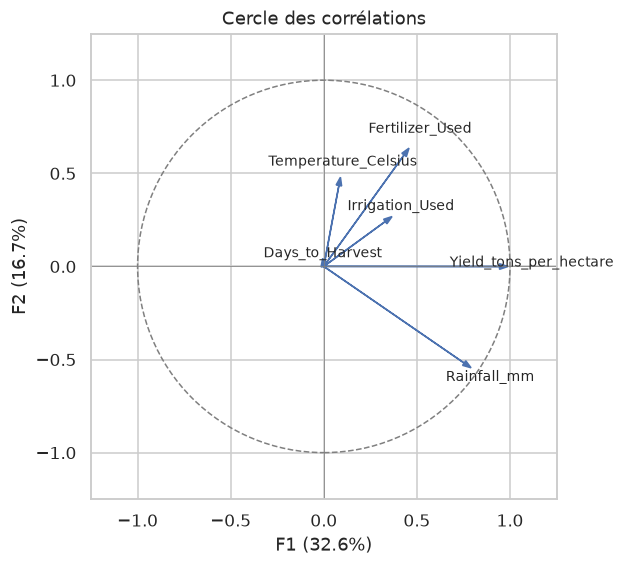

In [10]:
fig, ax = plt.subplots(figsize=(5.8, 5.8))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", ls="--"))
for (x, y), nom in zip(charges[["F1", "F2"]].to_numpy(), colonnes_acp):
    ax.arrow(0, 0, x, y, head_width=0.03, color="#4C72B0", length_includes_head=True)
    ax.text(x * 1.13, y * 1.13, nom, ha="center", fontsize=9)
ax.axhline(0, c="grey", lw=0.5)
ax.axvline(0, c="grey", lw=0.5)
ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-1.25, 1.25)
ax.set_aspect("equal")
ax.set_xlabel(f"F1 ({acp.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"F2 ({acp.explained_variance_ratio_[1]:.1%})")
ax.set_title("Cercle des corrélations")
utils.enregistre("02_cercle_correlations")
plt.show()

**Observations :**

- **F1 associe le rendement, la pluie, l'engrais et l'irrigation**, tous de même signe :
  c'est l'axe de la productivité, et il résume le message de l'EDA.
- `Days_to_Harvest` et `Temperature_Celsius` restent courtes sur ce plan : elles ne
  participent pas à la structure principale.

# Projection des individus

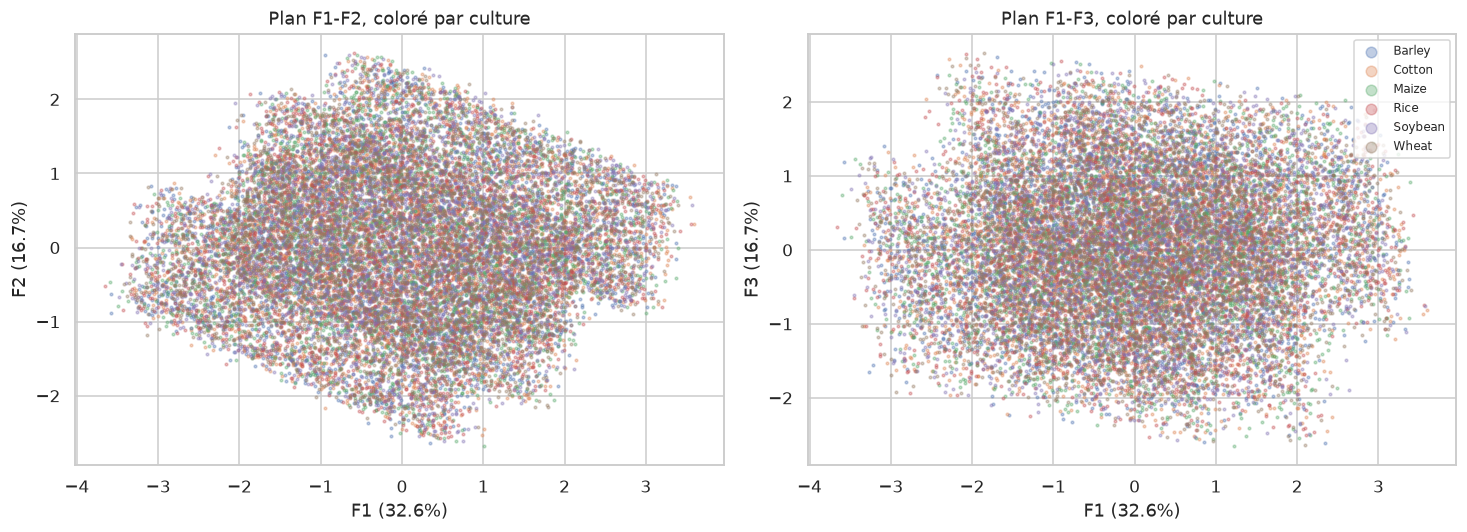

In [11]:
# 20,000 points are enough to judge a separation; beyond that the cloud saturates.
echantillon = df.sample(20_000, random_state=config.SEED)
projection = acp.transform(
    StandardScaler().fit(X).transform(echantillon[colonnes_acp].astype(float))
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2)]):
    for culture in echantillon["Crop"].cat.categories:
        masque = (echantillon["Crop"] == culture).to_numpy()
        ax.scatter(projection[masque, i], projection[masque, j], s=3, alpha=0.35,
                   label=culture)
    ax.set_xlabel(f"F{i+1} ({acp.explained_variance_ratio_[i]:.1%})")
    ax.set_ylabel(f"F{j+1} ({acp.explained_variance_ratio_[j]:.1%})")
    ax.set_title(f"Plan F{i+1}-F{j+1}, coloré par culture")
axes[1].legend(markerscale=4, fontsize=8, loc="upper right")
utils.enregistre("02_projection_cultures")
plt.show()

**Observations :**

- **Aucune séparation entre cultures** : les six nuages se superposent entièrement sur
  les deux plans examinés.
- C'est la confirmation visuelle du constat du notebook 01 — la culture ne structure rien
  dans ce jeu.

# Conclusion

- **F1 est le seul axe qui se détache**, et il associe rendement, pluie, engrais et
  irrigation, tous de même signe : c'est l'axe de la productivité.
- **Sans la cible, aucun axe ne domine** (≈ 20 % chacun, 5 axes pour 90 %) : les
  variables explicatives sont peu corrélées entre elles.
- `Days_to_Harvest` ne présente aucune relation linéaire notable avec les autres
  variables ; elle reste à l'écart de la structure principale.
- **Aucun plan factoriel ne sépare les cultures.**

**Conséquences pour la suite :**

1. **Aucune réduction de dimension à l'étape 2.** L'ACP ne compresserait rien et
   détruirait l'interprétabilité, précieuse pour le rapport métier.
2. Une ACP étant non supervisée, elle ne peut pas hiérarchiser les variables selon leur
   utilité prédictive — elle ne regarde jamais la cible. Le classement des variables clés
   vient de l'EDA (corrélations, effets en t/ha) et sera confirmé à l'étape 2 par
   l'importance des variables du modèle retenu.
3. L'absence de séparation des cultures confirme qu'il faut chercher l'effet culture
   ailleurs : c'est l'objet des notebooks 03 à 05.